Based on [this](https://pytorch.org/tutorials/beginner/translation_transformer.html). The dependency on torchtext was removed after training (see /tg2fa_translit/decode.py)

*Training was done on Google Colab*

In [ ]:
import torch
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DEVICE

In [ ]:
import math
import pandas as pd
from timeit import default_timer
from typing import List

from torchtext.vocab import build_vocab_from_iterator

from torch import Tensor
import torch.nn as nn
from torch.utils.data import DataLoader

## Build vocabulary

In [ ]:
SRC_LANGUAGE = 'tg'
TGT_LANGUAGE = 'fa'

# All symbols
token_transform = {
    SRC_LANGUAGE:'абвгғдеёжзиӣйкқлмнопрстуӯфхҳчҷшъэюяь' + '-~ ',
    TGT_LANGUAGE:'ابپتثجچحخدذرزژسشصضطظعغفقکگلمنوهی' + 'هٔئّْآ' + '-ي\u200c ',
    }
vocab_transform = {}

# Define special symbols and indices
UNK_IDX, PAD_IDX, BOS_IDX, EOS_IDX = 0, 1, 2, 3
special_symbols = ['<unk>', '<pad>', '<bos>', '<eos>']

for ln in [SRC_LANGUAGE, TGT_LANGUAGE]:
    # Create torchtext's Vocab object
    vocab_transform[ln] = build_vocab_from_iterator(token_transform[ln],
                                                    min_freq=1,
                                                    specials=special_symbols,
                                                    special_first=True)

# Set ``UNK_IDX`` as the default index.
for ln in [SRC_LANGUAGE, TGT_LANGUAGE]:
    vocab_transform[ln].set_default_index(UNK_IDX)
    print(ln, 'vocab length =', len(vocab_transform[ln]))

## Encode, decode and translate

In [ ]:
# helper Module that adds positional encoding to the token embedding to introduce a notion of word order.
class PositionalEncoding(nn.Module):
    def __init__(self,
                 emb_size: int,
                 dropout: float,
                 maxlen: int = 5000):
        super(PositionalEncoding, self).__init__()
        den = torch.exp(- torch.arange(0, emb_size, 2) * math.log(10000) / emb_size)
        pos = torch.arange(0, maxlen).reshape(maxlen, 1)
        pos_embedding = torch.zeros((maxlen, emb_size))
        pos_embedding[:, 0::2] = torch.sin(pos * den)
        pos_embedding[:, 1::2] = torch.cos(pos * den)
        pos_embedding = pos_embedding.unsqueeze(-2)

        self.dropout = nn.Dropout(dropout)
        self.register_buffer('pos_embedding', pos_embedding)

    def forward(self, token_embedding: Tensor):
        return self.dropout(token_embedding + self.pos_embedding[:token_embedding.size(0), :])


# helper Module to convert tensor of input indices into corresponding tensor of token embeddings
class TokenEmbedding(nn.Module):
    def __init__(self, vocab_size: int, emb_size):
        super(TokenEmbedding, self).__init__()
        self.embedding = nn.Embedding(vocab_size, emb_size)
        self.emb_size = emb_size

    def forward(self, tokens: Tensor):
        return self.embedding(tokens.long()) * math.sqrt(self.emb_size)

In [ ]:
class Translation(nn.Module):
    def __init__(self,
                 ):
        pass
    def gready(self, model, src, src_mask, max_len, start_symbol):
    src = src.to(DEVICE)
    src_mask = src_mask.to(DEVICE)

    memory = model.encode(src, src_mask)
    ys = torch.ones(1, 1).fill_(start_symbol).type(torch.long).to(DEVICE)
    for i in range(max_len-1):
        memory = memory.to(DEVICE)
        tgt_mask = (generate_square_subsequent_mask(ys.size(0))
                    .type(torch.bool)).to(DEVICE)
        out = model.decode(ys, memory, tgt_mask)
        out = out.transpose(0, 1)
        prob = model.generator(out[:, -1])
        _, next_word = torch.max(prob, dim=1)
        next_word = next_word.item()

        ys = torch.cat([ys,
                        torch.ones(1, 1).type_as(src.data).fill_(next_word)], dim=0)
        if next_word == EOS_IDX:
            break
    return ys
    def forward(self):
        pass

In [ ]:
def generate_square_subsequent_mask(sz):
    mask = (torch.triu(torch.ones((sz, sz), device=DEVICE)) == 1).transpose(0, 1)
    mask = mask.float().masked_fill(mask == 0, float('-inf')).masked_fill(mask == 1, float(0.0))
    return mask


def create_mask(src, tgt):
    src_seq_len = src.shape[0]
    tgt_seq_len = tgt.shape[0]

    tgt_mask = generate_square_subsequent_mask(tgt_seq_len)
    src_mask = torch.zeros((src_seq_len, src_seq_len),device=DEVICE).type(torch.bool)

    src_padding_mask = (src == PAD_IDX).transpose(0, 1)
    tgt_padding_mask = (tgt == PAD_IDX).transpose(0, 1)
    return src_mask, tgt_mask, src_padding_mask, tgt_padding_mask

In [ ]:
# helper function to club together sequential operations
def sequential_transforms(*transforms):
    def func(txt_input):
        for transform in transforms:
            txt_input = transform(txt_input)
        return txt_input
    return func


# function to add BOS/EOS and create tensor for input sequence indices
def tensor_transform(token_ids: List[int]):
    return torch.cat((torch.tensor([BOS_IDX]),
                      torch.tensor(token_ids),
                      torch.tensor([EOS_IDX])))


# ``src`` and ``tgt`` language text transforms to convert raw strings into tensors indices
text_transform = {}
for ln in [SRC_LANGUAGE, TGT_LANGUAGE]:
    text_transform[ln] = sequential_transforms(vocab_transform[ln], #Numericalization
                                               tensor_transform) # Add BOS/EOS and create tensor


# function to collate data samples into batch tensors
def collate_fn(batch):
    src_batch, tgt_batch = [], []
    for src_sample, tgt_sample in batch:
        src_batch.append(text_transform[SRC_LANGUAGE](list(src_sample)))
        tgt_batch.append(text_transform[TGT_LANGUAGE](list(tgt_sample)))
    src_batch = torch.nn.utils.rnn.pad_sequence(src_batch, padding_value=PAD_IDX)
    tgt_batch = torch.nn.utils.rnn.pad_sequence(tgt_batch, padding_value=PAD_IDX)
    return src_batch, tgt_batch

In [ ]:
# function to generate output sequence using greedy algorithm
def greedy_decode(model, src, src_mask, max_len, start_symbol):
    src = src.to(DEVICE)
    src_mask = src_mask.to(DEVICE)

    memory = model.encode(src, src_mask)
    ys = torch.ones(1, 1).fill_(start_symbol).type(torch.long).to(DEVICE)
    for i in range(max_len-1):
        memory = memory.to(DEVICE)
        tgt_mask = (generate_square_subsequent_mask(ys.size(0))
                    .type(torch.bool)).to(DEVICE)
        out = model.decode(ys, memory, tgt_mask)
        out = out.transpose(0, 1)
        prob = model.generator(out[:, -1])
        _, next_word = torch.max(prob, dim=1)
        next_word = next_word.item()

        ys = torch.cat([ys,
                        torch.ones(1, 1).type_as(src.data).fill_(next_word)], dim=0)
        if next_word == EOS_IDX:
            break
    return ys


# actual function to translate input sentence into target language
def translate(model: torch.nn.Module, src_sentence: str):
    model.eval()
    src = text_transform[SRC_LANGUAGE](list(src_sentence)).view(-1, 1)
    num_tokens = src.shape[0]
    src_mask = (torch.zeros(num_tokens, num_tokens)).type(torch.bool)
    tgt_tokens = greedy_decode(
        model, src, src_mask, max_len=num_tokens + 5, start_symbol=BOS_IDX).flatten()
    return "".join(vocab_transform[TGT_LANGUAGE].lookup_tokens(list(tgt_tokens.cpu().numpy()))).replace("<bos>", "").replace("<eos>", "")

## Model

In [ ]:
# Seq2Seq Network
class Seq2SeqTransformer(nn.Module):
    def __init__(self,
                 num_encoder_layers: int,
                 num_decoder_layers: int,
                 emb_size: int,
                 nhead: int,
                 src_vocab_size: int,
                 tgt_vocab_size: int,
                 dim_feedforward: int = 256,
                 dropout: float = 0.01):
        super(Seq2SeqTransformer, self).__init__()
        self.transformer = nn.Transformer(d_model=emb_size,
                                       nhead=nhead,
                                       num_encoder_layers=num_encoder_layers,
                                       num_decoder_layers=num_decoder_layers,
                                       dim_feedforward=dim_feedforward,
                                       dropout=dropout)
        self.generator = nn.Linear(emb_size, tgt_vocab_size)
        self.src_tok_emb = TokenEmbedding(src_vocab_size, emb_size)
        self.tgt_tok_emb = TokenEmbedding(tgt_vocab_size, emb_size)
        self.positional_encoding = PositionalEncoding(
            emb_size, dropout=dropout)

    def forward(self,
                src: Tensor,
                trg: Tensor,
                src_mask: Tensor,
                tgt_mask: Tensor,
                src_padding_mask: Tensor,
                tgt_padding_mask: Tensor,
                memory_key_padding_mask: Tensor):
        src_emb = self.positional_encoding(self.src_tok_emb(src))
        tgt_emb = self.positional_encoding(self.tgt_tok_emb(trg))
        outs = self.transformer(src_emb, tgt_emb, src_mask, tgt_mask, None,
                                src_padding_mask, tgt_padding_mask, memory_key_padding_mask)
        return self.generator(outs)

    def encode(self, src: Tensor, src_mask: Tensor):
        return self.transformer.encoder(self.positional_encoding(
                            self.src_tok_emb(src)), src_mask)

    def decode(self, tgt: Tensor, memory: Tensor, tgt_mask: Tensor):
        return self.transformer.decoder(self.positional_encoding(
                          self.tgt_tok_emb(tgt)), memory,
                          tgt_mask)

In [ ]:
loss_fn = torch.nn.CrossEntropyLoss(ignore_index=PAD_IDX)


def train_epoch(train_iter, model, optimizer):
    model.train()
    losses = 0

    train_dataloader = DataLoader(train_iter, batch_size=128, collate_fn=collate_fn, shuffle=True)
    for src, tgt in train_dataloader:
        src = src.to(DEVICE)
        tgt = tgt.to(DEVICE)

        tgt_input = tgt[:-1, :]
        src_mask, tgt_mask, src_padding_mask, tgt_padding_mask = create_mask(src, tgt_input)

        logits = model(src, tgt_input, src_mask, tgt_mask, src_padding_mask, tgt_padding_mask, src_padding_mask)

        optimizer.zero_grad()

        tgt_out = tgt[1:, :]
        loss = loss_fn(logits.reshape(-1, logits.shape[-1]), tgt_out.reshape(-1))
        loss.backward()

        optimizer.step()
        losses += loss.item()

    return losses / len(list(train_dataloader))


def evaluate(val_iter, model):
    model.eval()
    losses = 0
    val_dataloader = DataLoader(val_iter, batch_size=128, collate_fn=collate_fn, shuffle=True)

    for src, tgt in val_dataloader:
        src = src.to(DEVICE)
        tgt = tgt.to(DEVICE)

        tgt_input = tgt[:-1, :]

        src_mask, tgt_mask, src_padding_mask, tgt_padding_mask = create_mask(src, tgt_input)

        logits = model(src, tgt_input, src_mask, tgt_mask, src_padding_mask, tgt_padding_mask, src_padding_mask)

        tgt_out = tgt[1:, :]
        loss = loss_fn(logits.reshape(-1, logits.shape[-1]), tgt_out.reshape(-1))
        losses += loss.item()

    return losses / len(list(val_dataloader))

## Training

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
train = pd.read_csv('drive/MyDrive/data/train.csv').dropna().drop_duplicates()
val = pd.read_csv('drive/MyDrive/data/val.csv').dropna().drop_duplicates()
test = pd.read_csv('drive/MyDrive/data/test.csv').dropna().drop_duplicates()

print('Train length =', len(train))
print('Val length =', len(val))
print('Test length =', len(test))

train = [(i, j) for i, j in zip(train['tg'], train['fa'])]
val = [(i, j) for i, j in zip(val['tg'], val['fa'])]

Train length = 4252825
Val length = 254240
Test length = 2256


In [ ]:
torch.manual_seed(42)

SRC_VOCAB_SIZE = len(vocab_transform[SRC_LANGUAGE])
TGT_VOCAB_SIZE = len(vocab_transform[TGT_LANGUAGE])
EMB_SIZE = 64
NHEAD = 8
FFN_HID_DIM = 64
BATCH_SIZE = 128
NUM_ENCODER_LAYERS = 3
NUM_DECODER_LAYERS = 3

transformer = Seq2SeqTransformer(NUM_ENCODER_LAYERS, NUM_DECODER_LAYERS, EMB_SIZE,
                                 NHEAD, SRC_VOCAB_SIZE, TGT_VOCAB_SIZE, FFN_HID_DIM)

for p in transformer.parameters():
    if p.dim() > 1:
        nn.init.xavier_uniform_(p)

transformer = transformer.to(DEVICE)

optimizer = torch.optim.Adam(transformer.parameters(), lr=0.003, betas=(0.9, 0.98), eps=1e-9)

epoch = 0
val_loss = []
train_loss = []

transformer.eval()

/usr/local/lib/python3.10/dist-packages/torch/nn/modules/transformer.py:282: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.batch_first was not True(use batch_first for better inference performance)
  warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")


Seq2SeqTransformer(
  (transformer): Transformer(
    (encoder): TransformerEncoder(
      (layers): ModuleList(
        (0-2): 3 x TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
          )
          (linear1): Linear(in_features=64, out_features=64, bias=True)
          (dropout): Dropout(p=0.01, inplace=False)
          (linear2): Linear(in_features=64, out_features=64, bias=True)
          (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
          (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
          (dropout1): Dropout(p=0.01, inplace=False)
          (dropout2): Dropout(p=0.01, inplace=False)
        )
      )
      (norm): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    )
    (decoder): TransformerDecoder(
      (layers): ModuleList(
        (0-2): 3 x TransformerDecoderLayer(
          (self_attn): MultiheadAttention(
 

In [ ]:
for _ in range(8):
    epoch += 1
    train_loss.append(train_epoch(train, transformer, optimizer))
    val_loss.append(evaluate(val, transformer))

    torch.save({
        'epoch': epoch,
        'model_state_dict': transformer.state_dict(),
        'optimizer_state_dict': optimizer.state_dict(),
        'val_loss': val_loss,
        'train_loss' : train_loss,
        }, f'model_{epoch}')
    !cp model_$epoch /content/drive/MyDrive/models

    optimizer.step()

## Evaluation

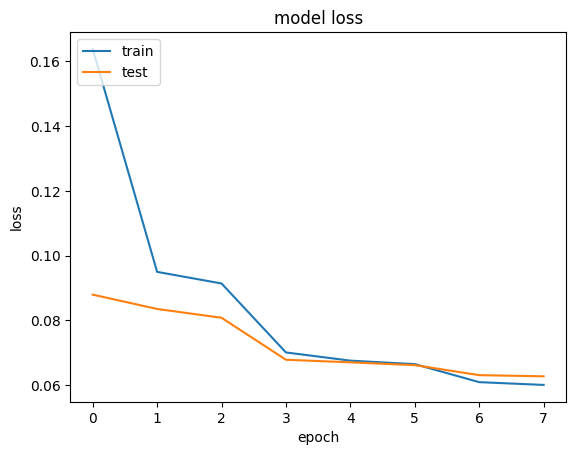

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns

# summarize history for loss
plt.plot(train_loss)
plt.plot(val_loss)
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

In [ ]:
start_time = default_timer()
test['test'] = test['tg'].apply(lambda x: translate(transformer, x))
end_time = default_timer()
print('Mean time =', f'{(end_time - start_time)/len(test):.3f} s')

Mean time = 0.095 s


In [ ]:
!pip install Levenshtein

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 169.4/169.4 kB 3.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 27.7 MB/s eta 0:00:00


In [ ]:
from Levenshtein import ratio, distance

test['ratio'] = test.apply(lambda x: ratio(x.fa, x.test), axis=1)
test['distance'] = test.apply(lambda x: distance(x.fa, x.test), axis=1)

In [ ]:
def accuracy(refs, preds):
    refs = refs.strip().split()
    preds = preds.strip().split()
    right_words = sum(word in preds for word in refs)
    return right_words / max(len(preds), len(refs))

test['accuracy'] = test.apply(lambda x: accuracy(x.fa, x.test), axis=1)

Accuracy = 0.825
Relative accuracy = 0.925
Ratio = 0.988
Distance = 0.287


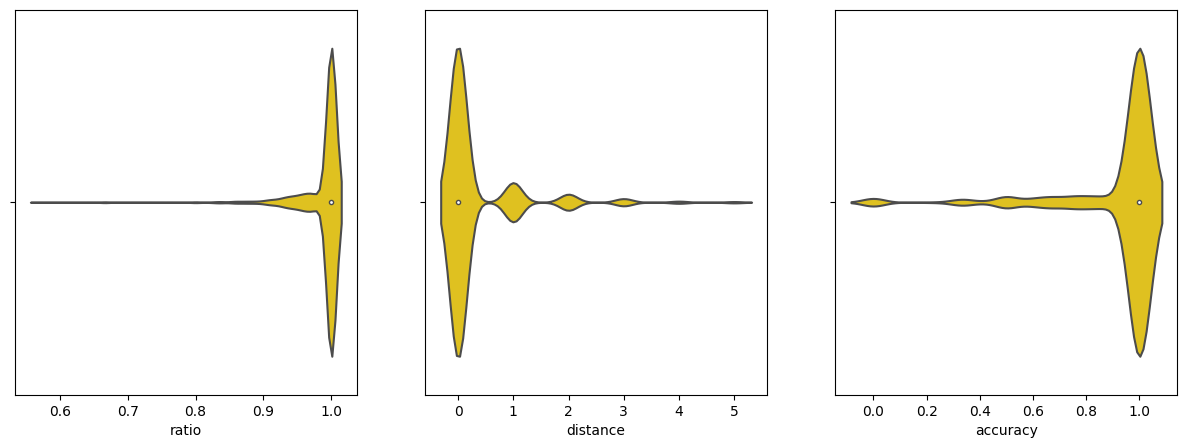

In [ ]:
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(15, 5))

for idx, column_name in enumerate(test[['ratio', 'distance', 'accuracy']]):
    plt.subplot(1, 3, idx + 1)
    sns.violinplot(data=test, color="gold",
                 x=column_name)

print(f'Accuracy = {(len(test[test["ratio"]==1]) / len(test)):.3f}')
print(f'Relative accuracy = {(test["accuracy"].sum() / len(test)):.3f}')
print(f'Ratio = {(test["ratio"].sum() / len(test)):.3f}')
print(f'Distance = {(test["distance"].sum() / len(test)):.3f}')

In [ ]:
test.describe()

,ratio,distance,accuracy
count,2256.000000,2256.000000,2256.000000
mean,0.988388,0.286791,0.925151
std,0.034268,0.737782,0.196767
min,0.571429,0.000000,0.000000
25%,1.000000,0.000000,1.000000
50%,1.000000,0.000000,1.000000
75%,1.000000,0.000000,1.000000
max,1.000000,5.000000,1.000000


In [ ]:
example = ['тамоми одамон озод ба дунё меоянд ва',
           'аз лиҳози манзилату ҳуқуқ бо ҳам баробаранд',
           'ҳама соҳиби ақлу виҷдонанд',
           'бояд нисбат ба якдигар бародарвор муносабат намоянд']
result = ['تمام آدمان آزاد به دنیا می‌آیند و',
          'از لحاظ منزلت و حقوق با هم برابرند',
          'همه صاحب عقل و وجدانند',
          'باید نسبت به یکدیگر برادروار مناسبت نمایند']
for t, f in zip(example, result):
    t2 = translate(transformer, t)
    print('>', t2)
    print('+', f)
    print('Ratio:', ratio(t2, f))

> تمام آدمان آزاد به دنیا می‌آیند و
+ تمام آدمان آزاد به دنیا می‌آیند و
Ratio: 1.0
> از لحاظ منزلت و حقوق با هم برابرند
+ از لحاظ منزلت و حقوق با هم برابرند
Ratio: 1.0
> همه صاحب عقل و وجدانند
+ همه صاحب عقل و وجدانند
Ratio: 1.0
> باید نسبت به یکدیگر برادروار مناسبت نمایند
+ باید نسبت به یکدیگر برادروار مناسبت نمایند
Ratio: 1.0
